# Nomenclator Glyph Separation

## Motivation

Notebook 29 (cipher-type diagnostics) established that the Voynich text behaves
like **natural language / monoalphabetic substitution** on every classical test, yet
16 monoalphabetic models fail to break it. This **central paradox** leaves two
viable hypotheses:

1. **Nomenclator** — a mixed cipher combining letter-substitution glyphs with
   code-word glyphs (each representing a whole word or concept). Dominant in
   15th-century Italian diplomatic cryptography; statistically indistinguishable
   from natural language.
2. **Constructed language** — an artificial system with language-like statistics
   but no natural-language substrate.

This notebook tests hypothesis (1) by attempting to **statistically separate**
the 166 STA1 glyphs into two populations:

- **Letter-glyphs**: behave like substitution-cipher symbols (high combinatorics,
  position-flexible, diverse contexts)
- **Code-glyphs**: behave like logographic tokens (restricted positions, limited
  combinations, self-contained semantics)

If the separation succeeds and the letter-subset deciphers better than the full
vocabulary, it supports the nomenclator hypothesis.

## Method

1. Extract 8 statistical features per glyph (frequency, positional entropy,
   left/right diversity, word-position distribution, bigram regularity)
2. Cluster with Gaussian Mixture Model (k=2) + validation (silhouette, BIC)
3. Attempt Neural v2 decipherment on letter-only subset
4. Compare with full-vocabulary baseline (68% n-gram from notebook 14)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''  # CPU-only for fork-safe multiprocessing

import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import multiprocessing as mp

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from scipy.spatial.distance import jensenshannon
from tqdm.notebook import tqdm

from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')
plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})
DEVICE = torch.device('cpu')
N_CPUS = os.cpu_count() or 4
N_WORKERS = min(N_CPUS - 1, 10)
print(f'Device: {DEVICE}, CPUs: {N_CPUS}, workers: {N_WORKERS}')

# ── Parser STA1 2.0 ─────────────────────────────────────────────────
def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens

def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras

# ── Load corpus ──
STA_PATH = 'corpus/voynich_sta.txt'
tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
glyph_freq = Counter(corpus_plano)

print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} glyphs, {len(VOCAB)} types')

Device: cpu, CPUs: 16, workers: 10
Voynich: 37,087 words, 157,254 glyphs, 166 types


Feature matrix: (166, 8) (glyphs × features)

Feature statistics (raw):
       log_freq  pos_entropy  left_div  right_div  right_H   left_H  onset_ratio  wl_diversity
count   166.000      166.000   166.000    166.000  166.000  166.000      166.000       166.000
mean      0.222        0.283     0.367      0.493    0.137    0.119        0.384         0.290
std       0.222        0.311     0.401      0.427    0.154    0.150        0.403         0.303
min       0.058       -0.000     0.000      0.000   -0.000    0.000        0.000         0.059
25%       0.058        0.000     0.003      0.033    0.000    0.000        0.000         0.059
50%       0.135        0.132     0.180      0.500    0.097   -0.000        0.236         0.118
75%       0.284        0.579     0.667      1.000    0.278    0.244        0.750         0.412
max       0.847        0.966     1.000      1.000    0.487    0.525        1.000         1.000


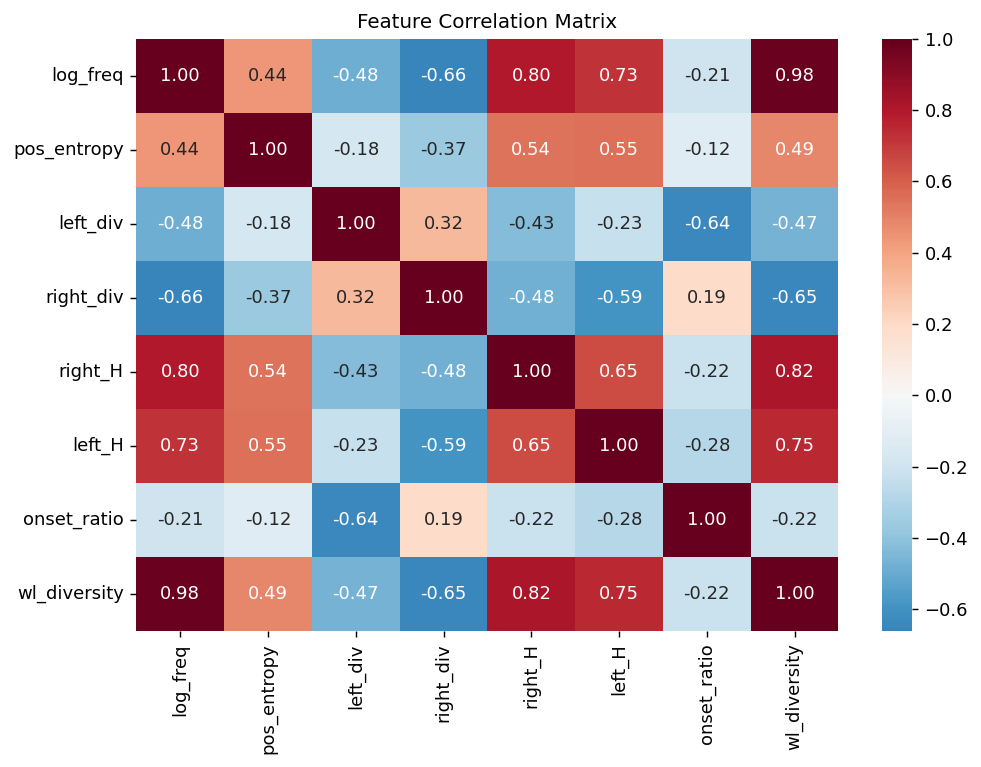

Saved: images/nomenclator_feature_corr.png


In [2]:
# ── Feature engineering: 8 features per glyph ────────────────────────

def compute_glyph_features(palabras, VOCAB, glyph_freq):
    N_total = sum(glyph_freq.values())
    features = {}

    # Pre-compute word-level positions
    onset_counts = Counter()
    coda_counts = Counter()
    middle_counts = Counter()
    total_counts = Counter()

    for w in palabras:
        for i, g in enumerate(w):
            total_counts[g] += 1
            if i == 0:
                onset_counts[g] += 1
            elif i == len(w) - 1:
                coda_counts[g] += 1
            else:
                middle_counts[g] += 1

    # Left and right context diversity
    left_ctx = defaultdict(set)
    right_ctx = defaultdict(set)
    left_counts = defaultdict(Counter)
    right_counts = defaultdict(Counter)

    for w in palabras:
        for i, g in enumerate(w):
            if i > 0:
                left_ctx[g].add(w[i-1])
                left_counts[g][w[i-1]] += 1
            if i < len(w) - 1:
                right_ctx[g].add(w[i+1])
                right_counts[g][w[i+1]] += 1

    # Bigram predictability: how predictable is the next glyph given this one?
    # H(next | this) — low = predictable = more code-like
    def context_entropy(counter):
        total = sum(counter.values())
        if total == 0:
            return 0.0
        return -sum((c/total) * math.log2(c/total) for c in counter.values())

    # Word-length distribution: in how many different word lengths does this glyph appear?
    glyph_wordlens = defaultdict(Counter)
    for w in palabras:
        wl = len(w)
        for g in set(w):
            glyph_wordlens[g][wl] += 1

    for g in VOCAB:
        freq = glyph_freq[g]
        total = total_counts[g]
        if total == 0:
            features[g] = [0.0] * 8
            continue

        # F1: Log frequency (normalized)
        f1_logfreq = math.log2(freq + 1) / math.log2(N_total)

        # F2: Positional entropy — how evenly distributed across O/M/C positions
        pos_vec = [onset_counts[g], middle_counts[g], coda_counts[g]]
        pos_total = sum(pos_vec)
        if pos_total > 0:
            pos_probs = [p / pos_total for p in pos_vec]
            f2_pos_entropy = -sum(p * math.log2(p) for p in pos_probs if p > 0)
            f2_pos_entropy /= math.log2(3)  # normalize to [0,1]
        else:
            f2_pos_entropy = 0.0

        # F3: Left context diversity (unique left neighbors / freq)
        f3_left_div = len(left_ctx[g]) / max(total, 1)

        # F4: Right context diversity
        f4_right_div = len(right_ctx[g]) / max(total, 1)

        # F5: Right context entropy (predictability of next glyph)
        f5_right_entropy = context_entropy(right_counts[g])
        # Normalize by log2(|VOCAB|)
        f5_right_entropy /= max(math.log2(len(VOCAB)), 1)

        # F6: Left context entropy
        f6_left_entropy = context_entropy(left_counts[g])
        f6_left_entropy /= max(math.log2(len(VOCAB)), 1)

        # F7: Onset ratio — fraction of occurrences at word start
        f7_onset_ratio = onset_counts[g] / total

        # F8: Word-length diversity — how many different word lengths
        f8_wl_diversity = len(glyph_wordlens[g]) / max(max(len(w) for w in palabras), 1)

        features[g] = [f1_logfreq, f2_pos_entropy, f3_left_div, f4_right_div,
                        f5_right_entropy, f6_left_entropy, f7_onset_ratio, f8_wl_diversity]

    return features

feature_names = ['log_freq', 'pos_entropy', 'left_div', 'right_div',
                 'right_H', 'left_H', 'onset_ratio', 'wl_diversity']

glyph_features = compute_glyph_features(palabras, VOCAB, glyph_freq)

# Build feature matrix
X_raw = np.array([glyph_features[g] for g in VOCAB])
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print(f'Feature matrix: {X.shape} (glyphs × features)')
print(f'\nFeature statistics (raw):')
df_feat = pd.DataFrame(X_raw, index=VOCAB, columns=feature_names)
print(df_feat.describe().round(3).to_string())

# ── Feature correlation ──
fig, ax = plt.subplots(figsize=(8, 6))
corr = df_feat.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Feature Correlation Matrix')
plt.tight_layout()
plt.savefig('images/nomenclator_feature_corr.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/nomenclator_feature_corr.png')

## Clustering: Separating Letter-Glyphs from Code-Glyphs

We apply three clustering methods to find two populations:
1. **Gaussian Mixture Model (GMM)** — probabilistic, allows soft assignment
2. **K-Means** — centroid-based, hard assignment
3. **Spectral Clustering** — graph-based, captures non-linear structure

We validate with:
- **Silhouette score** — how well-separated are the clusters?
- **BIC** for GMM — does k=2 fit better than k=1 or k=3?
- **Cluster size ratio** — nomenclators typically have 60-80% letter-glyphs, 20-40% code-glyphs

=== CLUSTERING RESULTS ===

GMM k=2:      silhouette=0.268, sizes=[123  43]
K-Means k=2:  silhouette=0.397, sizes=[111  55]
Spectral k=2: silhouette=0.274, sizes=[128  38]

BIC scan:
  k=1: BIC=2582.6
  k=2: BIC=1140.2
  k=3: BIC=-708.6
  k=4: BIC=-1158.6
  k=5: BIC=-1609.8
  k=6: BIC=-2486.3 ← BEST

Agreement (Adjusted Rand Index):
  GMM vs K-Means:  0.002
  GMM vs Spectral: 0.874
  K-Means vs Spectral: -0.024

=== POPULATION ASSIGNMENT (GMM) ===
Letter-glyphs: 123 (74.1%)
Code-glyphs:   43 (25.9%)


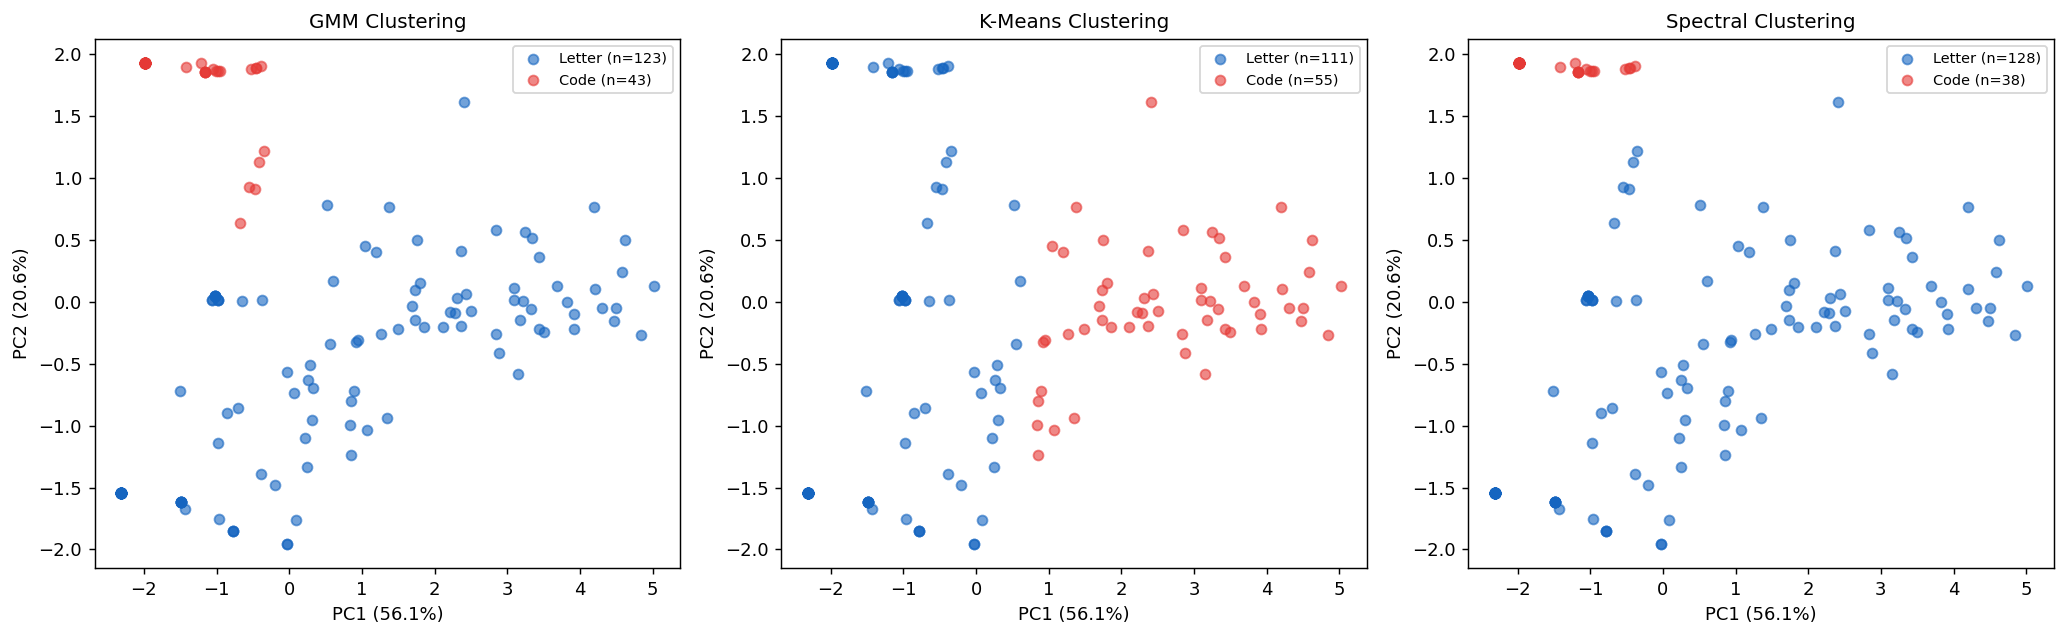

Saved: images/nomenclator_clustering.png


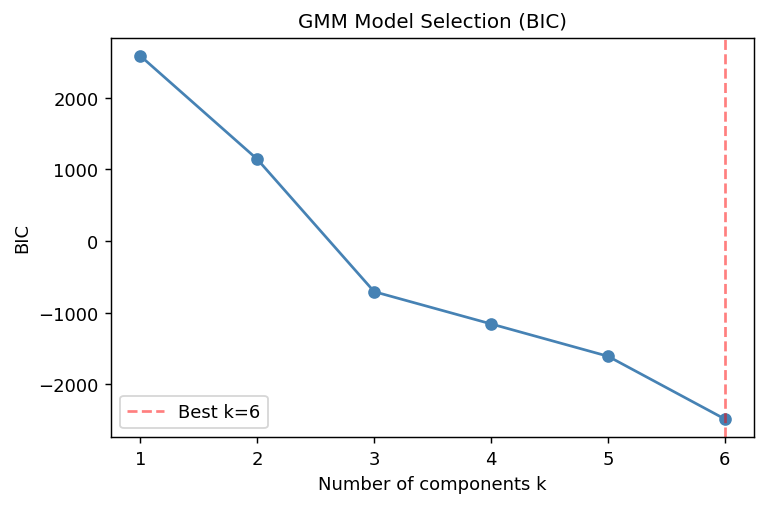

Saved: images/nomenclator_bic.png


In [3]:
# ── Clustering ───────────────────────────────────────────────────────
np.random.seed(42)

# GMM with k=2
gmm2 = GaussianMixture(n_components=2, covariance_type='full',
                        n_init=10, random_state=42)
labels_gmm = gmm2.fit_predict(X)
probs_gmm = gmm2.predict_proba(X)

# K-Means with k=2
km2 = KMeans(n_clusters=2, n_init=20, random_state=42)
labels_km = km2.fit_predict(X)

# Spectral Clustering with k=2
sc2 = SpectralClustering(n_clusters=2, affinity='rbf', random_state=42, n_init=10)
labels_sc = sc2.fit_predict(X)

# ── BIC scan for GMM (k=1..6) ──
bic_scores = []
for k in range(1, 7):
    gmm_k = GaussianMixture(n_components=k, covariance_type='full',
                             n_init=10, random_state=42)
    gmm_k.fit(X)
    bic_scores.append((k, gmm_k.bic(X)))

# ── Silhouette scores ──
sil_gmm = silhouette_score(X, labels_gmm)
sil_km = silhouette_score(X, labels_km)
sil_sc = silhouette_score(X, labels_sc)

print('=== CLUSTERING RESULTS ===')
print(f'\nGMM k=2:      silhouette={sil_gmm:.3f}, sizes={np.bincount(labels_gmm)}')
print(f'K-Means k=2:  silhouette={sil_km:.3f}, sizes={np.bincount(labels_km)}')
print(f'Spectral k=2: silhouette={sil_sc:.3f}, sizes={np.bincount(labels_sc)}')

print(f'\nBIC scan:')
for k, bic in bic_scores:
    best_marker = ' ← BEST' if bic == min(b for _, b in bic_scores) else ''
    print(f'  k={k}: BIC={bic:.1f}{best_marker}')

best_bic_k = min(bic_scores, key=lambda x: x[1])[0]

# ── Agreement between methods ──
from sklearn.metrics import adjusted_rand_score
ari_gmm_km = adjusted_rand_score(labels_gmm, labels_km)
ari_gmm_sc = adjusted_rand_score(labels_gmm, labels_sc)
ari_km_sc = adjusted_rand_score(labels_km, labels_sc)
print(f'\nAgreement (Adjusted Rand Index):')
print(f'  GMM vs K-Means:  {ari_gmm_km:.3f}')
print(f'  GMM vs Spectral: {ari_gmm_sc:.3f}')
print(f'  K-Means vs Spectral: {ari_km_sc:.3f}')

# ── Use GMM as primary (probabilistic) ──
# Label the larger cluster as "letter" (nomenclators have more letter-glyphs)
cluster_sizes = np.bincount(labels_gmm)
letter_label = np.argmax(cluster_sizes)
code_label = 1 - letter_label

letter_glyphs = [VOCAB[i] for i in range(len(VOCAB)) if labels_gmm[i] == letter_label]
code_glyphs = [VOCAB[i] for i in range(len(VOCAB)) if labels_gmm[i] == code_label]

print(f'\n=== POPULATION ASSIGNMENT (GMM) ===')
print(f'Letter-glyphs: {len(letter_glyphs)} ({100*len(letter_glyphs)/len(VOCAB):.1f}%)')
print(f'Code-glyphs:   {len(code_glyphs)} ({100*len(code_glyphs)/len(VOCAB):.1f}%)')

# ── PCA visualization ──
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, labels, title in zip(axes, [labels_gmm, labels_km, labels_sc],
                               ['GMM', 'K-Means', 'Spectral']):
    for lab, color, name in [(letter_label, '#1565C0', 'Letter'),
                              (code_label, '#E53935', 'Code')]:
        mask = labels == lab
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, alpha=0.6,
                   s=30, label=f'{name} (n={mask.sum()})')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    ax.set_title(f'{title} Clustering')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('images/nomenclator_clustering.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/nomenclator_clustering.png')

# BIC plot
fig, ax = plt.subplots(figsize=(6, 4))
ks = [k for k, _ in bic_scores]
bics = [b for _, b in bic_scores]
ax.plot(ks, bics, '-o', color='steelblue')
ax.set_xlabel('Number of components k')
ax.set_ylabel('BIC')
ax.set_title('GMM Model Selection (BIC)')
ax.axvline(best_bic_k, ls='--', color='red', alpha=0.5, label=f'Best k={best_bic_k}')
ax.legend()
plt.tight_layout()
plt.savefig('images/nomenclator_bic.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/nomenclator_bic.png')

=== FEATURE COMPARISON ===
        Feature  Letter mean    Code mean        Δ   t-stat
       log_freq       0.2683       0.0911  +0.1772     4.81 ***
    pos_entropy       0.3617       0.0574  +0.3043     6.09 ***
       left_div       0.4859       0.0279  +0.4580     7.44 ***
      right_div       0.4179       0.7076  -0.2897    -4.00 ***
        right_H       0.1700       0.0425  +0.1275     4.98 ***
         left_H       0.1604       0.0000  +0.1604     6.81 ***
    onset_ratio       0.1789       0.9721  -0.7932   -22.03 ***
   wl_diversity       0.3592       0.0917  +0.2675     5.38 ***

=== CORPUS COVERAGE ===
Letter tokens: 157,140 (99.9%)
Code tokens:   114 (0.1%)

Words by composition:
  All-letter: 36,973 (99.7%)
  All-code:   35 (0.1%)
  Mixed:      79 (0.2%)


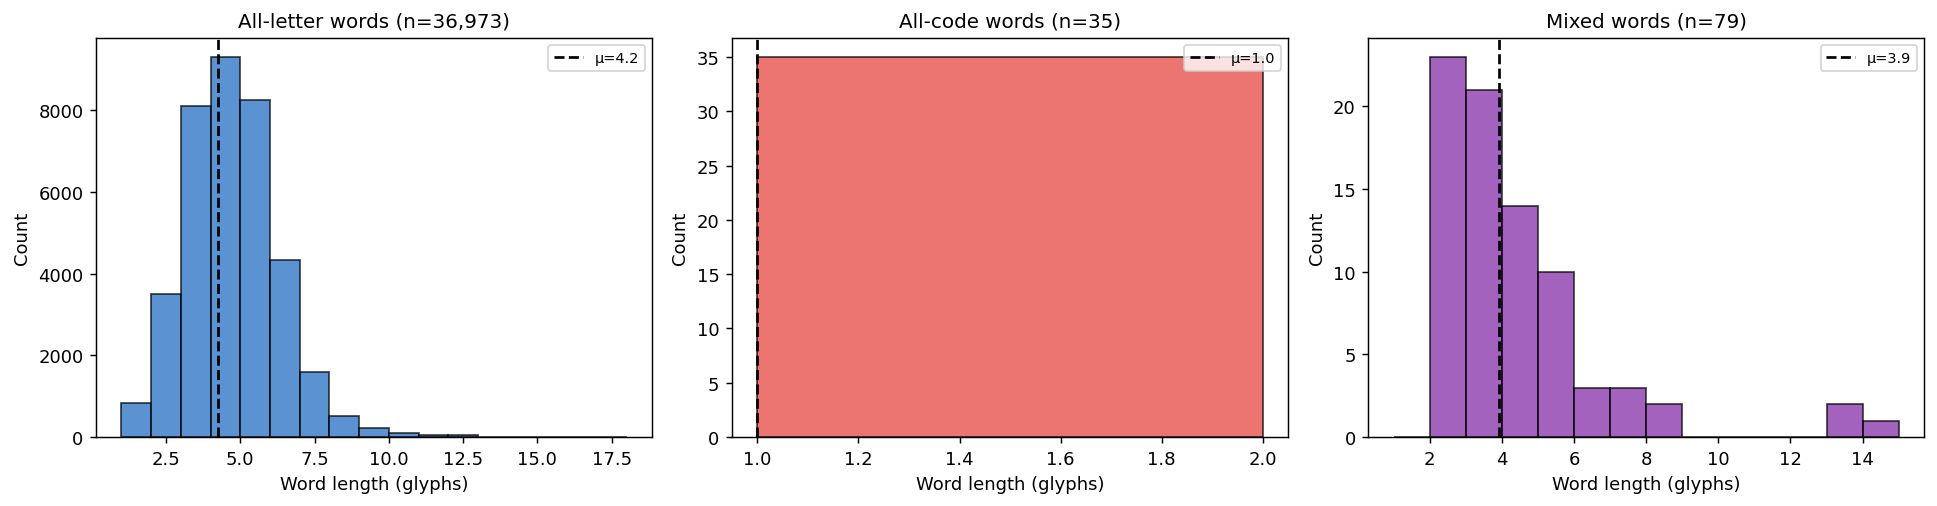

Saved: images/nomenclator_word_composition.png

=== TOP 20 LETTER-GLYPHS (by frequency) ===
  A1: freq=25106, P(letter)=1.000
  A2: freq=17464, P(letter)=1.000
  A3: freq=14545, P(letter)=1.000
  K1: freq=11066, P(letter)=1.000
  B2: freq=10668, P(letter)=1.000
  B1: freq=10492, P(letter)=1.000
  J1: freq=10257, P(letter)=1.000
  Q1: freq= 9935, P(letter)=1.000
  C1: freq= 6770, P(letter)=1.000
  Q2: freq= 6113, P(letter)=1.000
  D1: freq= 5425, P(letter)=1.000
  K2: freq= 4442, P(letter)=1.000
  L1: freq= 4174, P(letter)=1.000
  G1: freq= 4162, P(letter)=1.000
  C2: freq= 2837, P(letter)=1.000
  Ba: freq= 2714, P(letter)=1.000
  F1: freq= 1709, P(letter)=1.000
  P1: freq= 1442, P(letter)=1.000
  B3: freq= 1065, P(letter)=1.000
  U2: freq=  895, P(letter)=1.000

=== TOP 20 CODE-GLYPHS (by frequency) ===
  Da: freq=   10, P(code)=1.000
  U7: freq=   10, P(code)=1.000
  X2: freq=   10, P(code)=1.000
  Ta: freq=    9, P(code)=1.000
  Eb: freq=    6, P(code)=1.000
  Xb: freq=    6, P(code)

In [4]:
# ── Population analysis ──────────────────────────────────────────────

# Feature comparison between clusters
print('=== FEATURE COMPARISON ===')
print(f'{"Feature":>15} {"Letter mean":>12} {"Code mean":>12} {"Δ":>8} {"t-stat":>8}')
from scipy.stats import ttest_ind

for fi, fname in enumerate(feature_names):
    vals_letter = X_raw[[i for i in range(len(VOCAB)) if labels_gmm[i] == letter_label], fi]
    vals_code = X_raw[[i for i in range(len(VOCAB)) if labels_gmm[i] == code_label], fi]
    t_stat, p_val = ttest_ind(vals_letter, vals_code)
    delta = vals_letter.mean() - vals_code.mean()
    sig = '***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else ''
    print(f'{fname:>15} {vals_letter.mean():12.4f} {vals_code.mean():12.4f} '
          f'{delta:+8.4f} {t_stat:8.2f} {sig}')

# ── Corpus coverage ──
letter_set = set(letter_glyphs)
code_set = set(code_glyphs)

letter_tokens = sum(glyph_freq[g] for g in letter_glyphs)
code_tokens = sum(glyph_freq[g] for g in code_glyphs)
total_tokens = letter_tokens + code_tokens

# Words by composition
words_all_letter = [w for w in palabras if all(g in letter_set for g in w)]
words_all_code = [w for w in palabras if all(g in code_set for g in w)]
words_mixed = [w for w in palabras if any(g in letter_set for g in w) and any(g in code_set for g in w)]

print(f'\n=== CORPUS COVERAGE ===')
print(f'Letter tokens: {letter_tokens:,} ({100*letter_tokens/total_tokens:.1f}%)')
print(f'Code tokens:   {code_tokens:,} ({100*code_tokens/total_tokens:.1f}%)')
print(f'\nWords by composition:')
print(f'  All-letter: {len(words_all_letter):,} ({100*len(words_all_letter)/len(palabras):.1f}%)')
print(f'  All-code:   {len(words_all_code):,} ({100*len(words_all_code)/len(palabras):.1f}%)')
print(f'  Mixed:      {len(words_mixed):,} ({100*len(words_mixed)/len(palabras):.1f}%)')

# ── Word length distributions per composition ──
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, words_sub, title, color in [
    (axes[0], words_all_letter, f'All-letter words (n={len(words_all_letter):,})', '#1565C0'),
    (axes[1], words_all_code, f'All-code words (n={len(words_all_code):,})', '#E53935'),
    (axes[2], words_mixed, f'Mixed words (n={len(words_mixed):,})', '#7B1FA2'),
]:
    if words_sub:
        lens = [len(w) for w in words_sub]
        ax.hist(lens, bins=range(1, max(lens)+2), color=color, alpha=0.7, edgecolor='black')
        ax.set_xlabel('Word length (glyphs)')
        ax.set_ylabel('Count')
        ax.axvline(np.mean(lens), ls='--', color='black', label=f'μ={np.mean(lens):.1f}')
        ax.legend(fontsize=8)
    ax.set_title(title)

plt.tight_layout()
plt.savefig('images/nomenclator_word_composition.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/nomenclator_word_composition.png')

# ── Top glyphs in each cluster ──
print(f'\n=== TOP 20 LETTER-GLYPHS (by frequency) ===')
letter_sorted = sorted(letter_glyphs, key=lambda g: glyph_freq[g], reverse=True)
for i, g in enumerate(letter_sorted[:20]):
    prob = probs_gmm[VOCAB.index(g), letter_label]
    print(f'  {g}: freq={glyph_freq[g]:5d}, P(letter)={prob:.3f}')

print(f'\n=== TOP 20 CODE-GLYPHS (by frequency) ===')
code_sorted = sorted(code_glyphs, key=lambda g: glyph_freq[g], reverse=True)
for i, g in enumerate(code_sorted[:20]):
    prob = probs_gmm[VOCAB.index(g), code_label]
    print(f'  {g}: freq={glyph_freq[g]:5d}, P(code)={prob:.3f}')

# ── Nomenclator plausibility check ──
print(f'\n=== NOMENCLATOR PLAUSIBILITY ===')
letter_pct = 100 * len(letter_glyphs) / len(VOCAB)
code_pct = 100 * len(code_glyphs) / len(VOCAB)

checks = []
# Check 1: cluster ratio — expect 60-80% letter, 20-40% code
if 50 <= letter_pct <= 85:
    checks.append(('Cluster ratio', 'PASS', f'{letter_pct:.0f}% letter / {code_pct:.0f}% code'))
else:
    checks.append(('Cluster ratio', 'FAIL', f'{letter_pct:.0f}% letter / {code_pct:.0f}% code (expected 60-80/20-40)'))

# Check 2: silhouette > 0.2 (meaningful separation)
if sil_gmm > 0.2:
    checks.append(('Silhouette', 'PASS', f'{sil_gmm:.3f} > 0.2'))
elif sil_gmm > 0.1:
    checks.append(('Silhouette', 'MARGINAL', f'{sil_gmm:.3f} (weak separation)'))
else:
    checks.append(('Silhouette', 'FAIL', f'{sil_gmm:.3f} < 0.1 (no meaningful separation)'))

# Check 3: BIC prefers k=2 over k=1
bic_dict = dict(bic_scores)
if bic_dict.get(2, 0) < bic_dict.get(1, 0):
    checks.append(('BIC k=2 vs k=1', 'PASS', f'BIC(2)={bic_dict[2]:.0f} < BIC(1)={bic_dict[1]:.0f}'))
else:
    checks.append(('BIC k=2 vs k=1', 'FAIL', f'BIC(2)={bic_dict[2]:.0f} ≥ BIC(1)={bic_dict[1]:.0f}'))

# Check 4: method agreement (ARI > 0.5)
mean_ari = np.mean([ari_gmm_km, ari_gmm_sc, ari_km_sc])
if mean_ari > 0.5:
    checks.append(('Method agreement', 'PASS', f'mean ARI={mean_ari:.3f}'))
elif mean_ari > 0.3:
    checks.append(('Method agreement', 'MARGINAL', f'mean ARI={mean_ari:.3f}'))
else:
    checks.append(('Method agreement', 'FAIL', f'mean ARI={mean_ari:.3f} (methods disagree)'))

# Check 5: mixed words < 50% (nomenclator should have mostly pure words)
mixed_pct = 100 * len(words_mixed) / len(palabras)
if mixed_pct < 30:
    checks.append(('Mixed words', 'PASS', f'{mixed_pct:.1f}% mixed'))
elif mixed_pct < 50:
    checks.append(('Mixed words', 'MARGINAL', f'{mixed_pct:.1f}% mixed (high for nomenclator)'))
else:
    checks.append(('Mixed words', 'FAIL', f'{mixed_pct:.1f}% mixed (nomenclator predicts mostly pure words)'))

print(f'{"Check":>20} {"Result":>10} {"Detail"}')
n_pass = n_marg = n_fail = 0
for name, result, detail in checks:
    print(f'{name:>20} {result:>10} {detail}')
    if result == 'PASS': n_pass += 1
    elif result == 'MARGINAL': n_marg += 1
    else: n_fail += 1
print(f'\nScorecard: {n_pass}+ / {n_marg}± / {n_fail}−')

## Decipherment Test: Letter-Subset Only

If the nomenclator hypothesis is correct, restricting decipherment to letter-glyphs
should improve results because:
- The code-glyphs add noise to the substitution model (they don't map to individual letters)
- The letter-glyph subset should have a lower |Σ|/|A| ratio (closer to solvable range)
- N-gram scores should improve because we only score "readable" words

We test two approaches:
1. **Filter approach**: only decode words composed entirely of letter-glyphs
2. **Mask approach**: decode all words but mask code-glyphs as a special ⟨CODE⟩ token

In [5]:
# ── Hebrew corpus download ────────────────────────────────────────────

def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Total: {len(todas_palabras):,} words')
    return todas_palabras

print('Downloading Hebrew corpus (Torah)...')
hebrew_words_full = descargar_hebreo()

rng_sub = np.random.default_rng(42)
if len(hebrew_words_full) > N_VOYNICH:
    idx = rng_sub.choice(len(hebrew_words_full), size=N_VOYNICH, replace=False)
    hebrew_words = [hebrew_words_full[i] for i in sorted(idx)]
else:
    hebrew_words = hebrew_words_full
print(f'Subsampled: {len(hebrew_words):,} words')

# C/V classification
HEBREW_VOWELS = set('\u05D0\u05D4\u05D5\u05D9')  # אהוי
target_chars = sorted(set(c for w in hebrew_words for c in w))
char_role = {c: 'V' if c in HEBREW_VOWELS else 'C' for c in target_chars}
print(f'Hebrew: {len(target_chars)} chars')

# ── LSTM Architecture ────────────────────────────────────────────────

class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos = char2idx['<w>']
        eos = char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                ctx = indices[i-2:i]
                target = indices[i]
                self.samples.append((ctx, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ctx, target = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(target, dtype=torch.long)


class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0,
                           batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden

    def log_prob(self, word, temperature=1.0):
        self.eval()
        with torch.no_grad():
            bos = self.char2idx['<w>']
            eos = self.char2idx['</w>']
            unk = self.char2idx.get('<unk>', 0)
            indices = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
            total_lp = 0.0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, _ = self.forward(ctx)
                logits_t = logits[0, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                total_lp += log_probs[indices[i]].item() / math.log(2)
            return total_lp

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos = self.char2idx['<w>']
        eos = self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx, all_tgt = [], []
            word_boundaries = [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))
            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(palabras))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            CHUNK = 16384
            all_lps = []
            for start in range(0, n_total, CHUNK):
                end = min(start + CHUNK, n_total)
                logits, _ = self.forward(ctx_t[start:end])
                logits_last = logits[:, -1, :] / temperature
                log_p = torch.log_softmax(logits_last, dim=-1)
                target_lp = log_p.gather(1, tgt_t[start:end].unsqueeze(1)).squeeze(1)
                all_lps.append(target_lp)
            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)
            word_lps = np.zeros(len(palabras))
            for wi in range(len(palabras)):
                start = word_boundaries[wi]
                end = word_boundaries[wi + 1]
                if start < end:
                    word_lps[wi] = all_lps[start:end].sum()
            return word_lps

    def perplexity(self, words, temperature=1.0):
        self.eval()
        word_lps = self.batch_log_prob(words, temperature)
        total_lp = word_lps.sum()
        total_n = sum(len(w) + 1 for w in words)
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ── Build vocab and train ────────────────────────────────────────────
all_chars_heb = sorted(set(c for w in hebrew_words for c in w))
special_tokens = ['<pad>', '<w>', '</w>', '<unk>']
char_vocab = special_tokens + all_chars_heb
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}
print(f'Neural LM vocab: {len(char_vocab)} tokens')

rng_split = np.random.default_rng(42)
n_val = int(0.2 * len(hebrew_words))
perm = rng_split.permutation(len(hebrew_words))
val_idx = set(perm[:n_val])
train_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i not in val_idx]
val_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i in val_idx]

train_dataset = CharDataset(train_words, char2idx)
val_dataset = CharDataset(val_words, char2idx)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)

neural_lm = NeuralCharLM(len(char_vocab)).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char

optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

best_val_loss = float('inf')
patience_counter = 0
best_state_dict = None
train_losses, val_losses = [], []

print(f'Training Neural LM (30 epochs, patience=5)...')
t0 = time.time()

for epoch in range(30):
    neural_lm.train()
    epoch_loss, n_batches = 0.0, 0
    for ctx_batch, target_batch in train_loader:
        ctx_batch, target_batch = ctx_batch.to(DEVICE), target_batch.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = neural_lm(ctx_batch)
        loss = criterion(logits[:, -1, :], target_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    train_losses.append(epoch_loss / max(n_batches, 1))

    neural_lm.eval()
    vl, nvb = 0.0, 0
    with torch.no_grad():
        for ctx_batch, target_batch in val_loader:
            ctx_batch, target_batch = ctx_batch.to(DEVICE), target_batch.to(DEVICE)
            logits, _ = neural_lm(ctx_batch)
            loss = criterion(logits[:, -1, :], target_batch)
            vl += loss.item()
            nvb += 1
    val_loss = vl / max(nvb, 1)
    val_losses.append(val_loss)
    scheduler.step()

    if (epoch + 1) % 10 == 0:
        print(f'  Epoch {epoch+1}: train={train_losses[-1]:.4f}, val={val_loss:.4f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0
        best_state_dict = copy.deepcopy(neural_lm.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= 5:
            print(f'  Early stopping at epoch {epoch+1}')
            break

neural_lm.load_state_dict(best_state_dict)
print(f'Training done in {time.time()-t0:.1f}s, best val_loss={best_val_loss:.4f}')

  Descargando Genesis...
  Descargando Exodus...
  Descargando Leviticus...
  Descargando Numbers...
  Descargando Deuteronomy...
  Total: 80,051 words
Subsampled: 37,087 words
Hebrew: 27 chars
Neural LM vocab: 31 tokens
Training Neural LM (30 epochs, patience=5)...
  Epoch 10: train=2.0333, val=2.0167
  Epoch 20: train=2.0096, val=2.0059
  Epoch 30: train=1.9995, val=2.0036
Training done in 81.7s, best val_loss=2.0036


In [6]:
# ── EM pipeline (adapted for nomenclator subset) ────────────────────

# Grammar anchors
HEBREW_PREFIXES = set('\u05D5\u05D4\u05D1\u05DB\u05DC\u05DE\u05E9')  # והבכלמש
HEBREW_SUFFIXES = set('\u05D4\u05EA\u05DD\u05DF\u05DA')  # התםןך
HEBREW_ROOT_CONSONANTS = set('\u05D0\u05D1\u05D2\u05D3\u05D4\u05D5\u05D6\u05D7\u05D8\u05D9\u05DB\u05DC\u05DE\u05E0\u05E1\u05E2\u05E4\u05E6\u05E7\u05E8\u05E9\u05EA') - HEBREW_PREFIXES - HEBREW_SUFFIXES

# Root matching
HEBREW_CONSONANTS_SET = set('\u05D1\u05D2\u05D3\u05D4\u05D5\u05D6\u05D7\u05D8\u05D9\u05DB\u05DC\u05DE\u05E0\u05E1\u05E2\u05E4\u05E6\u05E7\u05E8\u05E9\u05EA') | set('\u05DA\u05DD\u05DF\u05E3\u05E5')
HEBREW_MATRES = set('\u05D0\u05D5\u05D9')  # אוי
HEBREW_ROOTS = {
    '\u05D0\u05DE\u05E8', '\u05D3\u05D1\u05E8', '\u05D4\u05D9\u05D4', '\u05D1\u05D5\u05D0', '\u05E2\u05E9\u05D4',
    '\u05E0\u05EA\u05DF', '\u05D9\u05D3\u05E2', '\u05D4\u05DC\u05DA', '\u05E8\u05D0\u05D4', '\u05E9\u05DE\u05E2',
    '\u05D0\u05DB\u05DC', '\u05DC\u05E7\u05D7', '\u05D9\u05E9\u05D1', '\u05E7\u05E8\u05D0', '\u05E9\u05DC\u05D7',
    '\u05E2\u05DC\u05D4', '\u05DE\u05D5\u05EA', '\u05E9\u05D5\u05D1', '\u05D1\u05E8\u05DA', '\u05D9\u05E6\u05D0',
    '\u05E2\u05D1\u05E8', '\u05E9\u05DE\u05E8', '\u05DB\u05EA\u05D1', '\u05E0\u05E9\u05D0', '\u05D6\u05DB\u05E8',
    '\u05D9\u05DC\u05D3', '\u05E2\u05DE\u05D3', '\u05E4\u05E0\u05D4', '\u05D1\u05E0\u05D4', '\u05E0\u05E4\u05DC',
    '\u05E9\u05D9\u05DD', '\u05D7\u05D9\u05D4', '\u05D2\u05D3\u05DC', '\u05E7\u05D5\u05DD', '\u05DE\u05DC\u05D0',
    '\u05DE\u05E6\u05D0', '\u05E9\u05E4\u05D8', '\u05D0\u05D4\u05D1', '\u05D9\u05E8\u05D3', '\u05E0\u05D2\u05D3',
    '\u05D9\u05E1\u05E3', '\u05D7\u05D8\u05D0', '\u05E7\u05D3\u05E9', '\u05DB\u05D4\u05DF', '\u05E6\u05D5\u05D4',
    '\u05D1\u05E8\u05D0', '\u05D2\u05DC\u05D4', '\u05D6\u05D1\u05D7', '\u05D8\u05D4\u05E8', '\u05D8\u05DE\u05D0',
    '\u05D0\u05E8\u05E5', '\u05D1\u05D9\u05EA', '\u05E9\u05E0\u05D4', '\u05D9\u05D5\u05DD', '\u05DE\u05D9\u05DD',
    '\u05E9\u05DE\u05E9', '\u05DC\u05D9\u05DC', '\u05D0\u05D1\u05DF', '\u05E2\u05D9\u05E8', '\u05D3\u05E8\u05DA',
    '\u05DE\u05DC\u05DA', '\u05DB\u05E1\u05E3', '\u05D6\u05D4\u05D1', '\u05D3\u05DE\u05DD', '\u05E8\u05D5\u05D7',
    '\u05E0\u05E4\u05E9', '\u05DC\u05D7\u05DD', '\u05E2\u05D9\u05DF', '\u05D9\u05D3\u05D3', '\u05E9\u05D3\u05D4',
    '\u05E2\u05D1\u05D3', '\u05DB\u05DC\u05D9', '\u05E4\u05E8\u05D9', '\u05D7\u05D3\u05E9', '\u05E1\u05E4\u05E8',
    '\u05E2\u05E6\u05DD', '\u05D1\u05E9\u05E8', '\u05D0\u05D3\u05DD', '\u05E0\u05D4\u05E8', '\u05D2\u05D1\u05E8',
    '\u05E8\u05D2\u05DC', '\u05E8\u05D0\u05E9', '\u05D7\u05D6\u05E7', '\u05E8\u05D1\u05D1', '\u05E7\u05D8\u05DF',
    '\u05D8\u05D5\u05D1', '\u05E8\u05E2\u05E2', '\u05D7\u05DB\u05DD', '\u05E6\u05D3\u05E7', '\u05E8\u05D7\u05DD',
    '\u05DB\u05D5\u05DC', '\u05D1\u05E7\u05E8', '\u05E6\u05D0\u05DF', '\u05E2\u05D5\u05E3', '\u05D3\u05D2\u05D2',
    '\u05E9\u05DE\u05DF', '\u05D9\u05D9\u05DF', '\u05E1\u05D5\u05E1', '\u05D2\u05DE\u05DC', '\u05D7\u05DE\u05E8',
}

def extract_skeleton_deterministic(mapped_word):
    skeleton = []
    for char in mapped_word:
        if char in HEBREW_MATRES:
            continue
        if char in HEBREW_CONSONANTS_SET:
            skeleton.append(char)
    return ''.join(skeleton)

def count_roots_quick(mapping_dict, palabras_sample, top_n=200):
    word_freq = Counter(tuple(w) for w in palabras_sample)
    top_words = word_freq.most_common(top_n)
    roots_matched = set()
    n_matches = 0
    for word_tuple, freq in top_words:
        mapped = [mapping_dict.get(g, '?') for g in word_tuple]
        skel = extract_skeleton_deterministic(mapped)
        if len(skel) < 3:
            continue
        for i in range(len(skel) - 2):
            trigram = skel[i:i+3]
            if trigram in HEBREW_ROOTS:
                roots_matched.add(trigram)
                n_matches += 1
    return roots_matched, n_matches


# ── Mapping state and scoring ────────────────────────────────────────

class GlyphMappingState:
    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role_map=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role_map or {}
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change_tracked(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new, glyph

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


def init_frequency_mapping(palabras_sub, vocab_glyphs, target_chars_list,
                           glyph_role_map, char_role_map):
    gf = Counter(g for p in palabras_sub for g in p)
    cf = Counter(c for w in hebrew_words for c in w)
    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role_map.get(g, '?') == role],
                          key=lambda g: gf.get(g, 0), reverse=True)
        if role == '?':
            chars_r = sorted(target_chars_list, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars_list if char_role_map.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars_list, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


def build_glyph_word_index(words):
    idx = defaultdict(list)
    for wi, word in enumerate(words):
        for g in set(word):
            idx[g].append(wi)
    return idx


def score_neural_lm_batch(mapping_state, words_sample, neural_lm_model, temperature=1.0):
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    word_lps = neural_lm_model.batch_log_prob(mapped, temperature)
    return float(np.mean(word_lps)), word_lps


def score_cardinality(mapping_state, K_max=23):
    K = len(set(mapping_state.mapping.values()))
    if K >= K_max:
        return 0.0
    return -((K_max - K) ** 2)


def score_entropy(mapping_state):
    char_counts = Counter(mapping_state.mapping.values())
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    return H / H_max if H_max > 1e-10 else 0.0


def score_positional(mapping_state, glyph_role_map, char_role_map):
    n_ok = sum(1 for g, c in mapping_state.mapping.items()
               if glyph_role_map.get(g, '?') == char_role_map.get(c, '?')
               and glyph_role_map.get(g) != '?')
    n_total = sum(1 for g in mapping_state.mapping if glyph_role_map.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_total_neural(mapping_state, words_sample, neural_lm_model, temperature,
                       glyph_role_map, char_role_map,
                       w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3, K_max=23):
    s_lm, word_lps = score_neural_lm_batch(mapping_state, words_sample, neural_lm_model, temperature)
    s_pos = score_positional(mapping_state, glyph_role_map, char_role_map)
    s_card = score_cardinality(mapping_state, K_max)
    s_ent = score_entropy(mapping_state)
    total = w_lm * s_lm + w_pos * s_pos + w_card * s_card + w_ent * s_ent
    return total, word_lps


def score_total_incremental(proposal, changed_glyph, words_sample, neural_lm_model,
                            temperature, glyph_role_map, char_role_map,
                            glyph_word_idx, prev_word_lps,
                            w_lm=2.0, w_pos=0.5, w_card=0.5, w_ent=0.3, K_max=23):
    new_word_lps = prev_word_lps.copy()
    affected = glyph_word_idx.get(changed_glyph, [])
    if affected:
        affected_mapped = [proposal.apply_word(words_sample[wi]) for wi in affected]
        new_lps = neural_lm_model.batch_log_prob(affected_mapped, temperature)
        for j, wi in enumerate(affected):
            new_word_lps[wi] = new_lps[j]
    s_lm = float(np.mean(new_word_lps))
    s_pos = score_positional(proposal, glyph_role_map, char_role_map)
    s_card = score_cardinality(proposal, K_max)
    s_ent = score_entropy(proposal)
    total = w_lm * s_lm + w_pos * s_pos + w_card * s_card + w_ent * s_ent
    return total, new_word_lps


print(f'EM pipeline loaded')
print(f'Hebrew roots: {len(HEBREW_ROOTS)}')

EM pipeline loaded
Hebrew roots: 100


In [7]:
# ── Run EM: Full vocabulary vs Letter-only (PARALLEL) ────────────────

# Build glyph_role for Voynich (simple C/V from positional analysis)
def build_simple_glyph_role(palabras, VOCAB_list):
    onset_c = Counter()
    coda_c = Counter()
    mid_c = Counter()
    for w in palabras:
        for i, g in enumerate(w):
            if i == 0:
                onset_c[g] += 1
            elif i == len(w) - 1:
                coda_c[g] += 1
            else:
                mid_c[g] += 1
    glyph_role_map = {}
    for g in VOCAB_list:
        total = onset_c[g] + coda_c[g] + mid_c[g]
        if total < 5:
            glyph_role_map[g] = '?'
        else:
            pct_mid = mid_c[g] / total
            glyph_role_map[g] = 'V' if pct_mid > 0.40 else 'C'
    return glyph_role_map

glyph_role_full = build_simple_glyph_role(palabras, VOCAB)

# Letter-only subset
VOCAB_LETTER = sorted(letter_set & set(VOCAB))
glyph_role_letter = {g: glyph_role_full.get(g, '?') for g in VOCAB_LETTER}
palabras_letter = [w for w in palabras if all(g in letter_set for g in w)]

print(f'Full vocab: {len(VOCAB)} glyphs, {len(palabras)} words')
print(f'Letter-only: {len(VOCAB_LETTER)} glyphs, {len(palabras_letter)} words')
print(f'|Σ|/|A| full: {len(VOCAB)/len(target_chars):.2f}')
print(f'|Σ|/|A| letter: {len(VOCAB_LETTER)/len(target_chars):.2f}')

# ── Parallel EM worker ──
def run_single_seed(args):
    seed_id, cond_name, palabras_em, vocab_em, glyph_role_em = args

    # Prevent PyTorch thread contention in forked workers
    torch.set_num_threads(1)

    T = 2.0
    sample_n = 1500
    n_iters = 1500
    patience = 80
    proposals_per_iter = 100

    rng = np.random.default_rng(42 + seed_id * 1000 + hash(cond_name) % 10000)
    sample_idx = rng.choice(len(palabras_em), size=min(sample_n, len(palabras_em)), replace=False)
    words_sample = [palabras_em[i] for i in sample_idx]
    glyph_word_idx = build_glyph_word_index(words_sample)

    state = GlyphMappingState(vocab_em, target_chars, glyph_role_em, char_role)
    init_map = init_frequency_mapping(palabras_em, vocab_em, target_chars,
                                      glyph_role_em, char_role)
    # Randomize 50%
    for g in vocab_em:
        if rng.random() < 0.5:
            role = glyph_role_em.get(g, '?')
            if role in ('C', 'V'):
                cands = [c for c in target_chars if char_role.get(c) == role]
            else:
                cands = target_chars
            init_map[g] = rng.choice(cands if cands else target_chars)
    state.set_mapping(init_map)

    best_score, best_word_lps = score_total_neural(
        state, words_sample, neural_lm, T, glyph_role_em, char_role)
    best_mapping = dict(state.mapping)
    no_improve = 0

    for iteration in range(n_iters):
        accepted = 0
        for _ in range(proposals_per_iter):
            proposal, changed = state.propose_change_tracked(rng, constrained=True)
            new_score, new_word_lps = score_total_incremental(
                proposal, changed, words_sample, neural_lm, T,
                glyph_role_em, char_role, glyph_word_idx, best_word_lps)
            if new_score > best_score:
                state = proposal
                best_score = new_score
                best_word_lps = new_word_lps
                best_mapping = dict(state.mapping)
                accepted += 1
                no_improve = 0
        if accepted == 0:
            no_improve += 1
        if no_improve >= patience:
            break

    roots, n_matches = count_roots_quick(best_mapping, palabras_em)
    return {
        'seed': seed_id, 'cond': cond_name, 'score': best_score,
        'mapping': best_mapping, 'roots': roots, 'n_roots': len(roots),
        'iterations': iteration + 1, 'K': len(set(best_mapping.values())),
    }

# ── Build job list ──
N_SEEDS = 10
all_args = []
for s in range(N_SEEDS):
    all_args.append((s, 'FULL', palabras, VOCAB, glyph_role_full))
    all_args.append((s, 'LETTER', palabras_letter, VOCAB_LETTER, glyph_role_letter))

print(f'\nRunning {len(all_args)} jobs (2 conditions x {N_SEEDS} seeds) on {N_WORKERS} workers...')
t0 = time.time()

ctx = mp.get_context('fork')
with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as pool:
    all_results = list(pool.map(run_single_seed, all_args, chunksize=1))

elapsed = time.time() - t0
print(f'All {len(all_results)} jobs done in {elapsed:.0f}s ({elapsed/60:.1f} min)')

# ── Separate results ──
results_full = [r for r in all_results if r['cond'] == 'FULL']
results_letter = [r for r in all_results if r['cond'] == 'LETTER']

print(f'\n=== FULL VOCABULARY ===')
for r in results_full:
    print(f"  Seed {r['seed']}: score={r['score']:.2f}, roots={r['n_roots']}, K={r['K']}, iters={r['iterations']}")

print(f'\n=== LETTER-ONLY ===')
for r in results_letter:
    print(f"  Seed {r['seed']}: score={r['score']:.2f}, roots={r['n_roots']}, K={r['K']}, iters={r['iterations']}")

Full vocab: 166 glyphs, 37087 words
Letter-only: 123 glyphs, 36973 words
|Σ|/|A| full: 6.15
|Σ|/|A| letter: 4.56

Running 20 jobs (2 conditions x 10 seeds) on 10 workers...
All 20 jobs done in 236s (3.9 min)

=== FULL VOCABULARY ===
  Seed 0: score=-34.68, roots=0, K=27, iters=218
  Seed 1: score=-36.10, roots=0, K=27, iters=336
  Seed 2: score=-34.49, roots=0, K=27, iters=258
  Seed 3: score=-34.31, roots=0, K=27, iters=305
  Seed 4: score=-33.41, roots=0, K=27, iters=250
  Seed 5: score=-34.80, roots=0, K=27, iters=293
  Seed 6: score=-34.42, roots=0, K=27, iters=219
  Seed 7: score=-35.52, roots=0, K=27, iters=283
  Seed 8: score=-34.17, roots=0, K=27, iters=222
  Seed 9: score=-34.26, roots=0, K=27, iters=185

=== LETTER-ONLY ===
  Seed 0: score=-34.14, roots=0, K=27, iters=281
  Seed 1: score=-34.43, roots=0, K=26, iters=153
  Seed 2: score=-34.09, roots=0, K=27, iters=197
  Seed 3: score=-34.41, roots=0, K=26, iters=224
  Seed 4: score=-36.02, roots=0, K=26, iters=177
  Seed 5: s

In [8]:
# ── Select best candidates ──
best_full = max(results_full, key=lambda r: (r['n_roots'], r['score']))
best_letter = max(results_letter, key=lambda r: (r['n_roots'], r['score']))

print('=== BEST CANDIDATES ===')
print(f'Full:   score={best_full["score"]:.2f}, roots={best_full["n_roots"]} '
      f'{best_full["roots"]}, K={len(set(best_full["mapping"].values()))}')
print(f'Letter: score={best_letter["score"]:.2f}, roots={best_letter["n_roots"]} '
      f'{best_letter["roots"]}, K={len(set(best_letter["mapping"].values()))}')

# ── Calibrate MCMC temperatures ──
def calibrate_T(mapping_init, palabras_cal, vocab_cal, glyph_role_cal, label=''):
    rng_cal = np.random.default_rng(99)
    state_cal = GlyphMappingState(vocab_cal, target_chars, glyph_role_cal, char_role)
    state_cal.set_mapping(mapping_init)
    cal_idx = rng_cal.choice(len(palabras_cal), size=min(1500, len(palabras_cal)), replace=False)
    cal_words = [palabras_cal[i] for i in cal_idx]
    cal_score, _ = score_total_neural(state_cal, cal_words, neural_lm, 2.0,
                                      glyph_role_cal, char_role)
    neg_deltas = []
    for _ in range(200):
        prop, ch = state_cal.propose_change_tracked(rng_cal, constrained=True)
        s, _ = score_total_neural(prop, cal_words, neural_lm, 2.0,
                                  glyph_role_cal, char_role)
        delta = s - cal_score
        if delta < 0:
            neg_deltas.append(-delta)
    T_mcmc = float(np.median(neg_deltas)) if neg_deltas else 1.0
    print(f'  [{label}] Calibrated T_mcmc={T_mcmc:.4f}')
    return T_mcmc

T_full = calibrate_T(best_full['mapping'], palabras, VOCAB, glyph_role_full, 'FULL')
T_letter = calibrate_T(best_letter['mapping'], palabras_letter, VOCAB_LETTER,
                        glyph_role_letter, 'LETTER')

# ── Parallel MCMC worker ──
def run_mcmc_chain(args):
    chain_id, cond_name, mapping_init, palabras_mc, vocab_mc, glyph_role_mc, T_mc = args

    torch.set_num_threads(1)

    n_iter = 15000
    burn_in = 3000
    thin = 10
    sample_n = 1500

    rng_mc = np.random.default_rng(1000 + chain_id + hash(cond_name) % 10000)
    mc_idx = rng_mc.choice(len(palabras_mc), size=min(sample_n, len(palabras_mc)), replace=False)
    mc_words = [palabras_mc[i] for i in mc_idx]
    mc_glyph_idx = build_glyph_word_index(mc_words)

    state = GlyphMappingState(vocab_mc, target_chars, glyph_role_mc, char_role)
    perturbed = dict(mapping_init)
    for g in vocab_mc:
        if rng_mc.random() < 0.1:
            role = glyph_role_mc.get(g, '?')
            cands = [c for c in target_chars if char_role.get(c) == role] if role in ('C','V') else target_chars
            perturbed[g] = rng_mc.choice(cands if cands else target_chars)
    state.set_mapping(perturbed)

    current_score, current_wlps = score_total_neural(
        state, mc_words, neural_lm, 2.0, glyph_role_mc, char_role)

    samples_map = []
    samples_score = []
    n_accepted = 0

    for it in range(n_iter):
        proposal, changed = state.propose_change_tracked(rng_mc, constrained=True)
        prop_score, prop_wlps = score_total_incremental(
            proposal, changed, mc_words, neural_lm, 2.0,
            glyph_role_mc, char_role, mc_glyph_idx, current_wlps)
        delta = prop_score - current_score
        if delta > 0 or rng_mc.random() < math.exp(delta / max(T_mc, 1e-10)):
            state = proposal
            current_score = prop_score
            current_wlps = prop_wlps
            n_accepted += 1

        if it >= burn_in and (it - burn_in) % thin == 0:
            samples_map.append(dict(state.mapping))
            samples_score.append(current_score)

    accept_rate = n_accepted / n_iter
    return {
        'chain_id': chain_id, 'cond': cond_name,
        'samples_map': samples_map, 'samples_score': samples_score,
        'accept_rate': accept_rate,
    }

# ── Run MCMC in parallel (8 chains: 4 full + 4 letter) ──
N_CHAINS = 4
mcmc_args = []
for c in range(N_CHAINS):
    mcmc_args.append((c, 'FULL', best_full['mapping'], palabras, VOCAB, glyph_role_full, T_full))
    mcmc_args.append((c, 'LETTER', best_letter['mapping'], palabras_letter, VOCAB_LETTER,
                      glyph_role_letter, T_letter))

print(f'\nRunning {len(mcmc_args)} MCMC chains on {N_WORKERS} workers...')
t0 = time.time()

ctx = mp.get_context('fork')
with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as pool:
    mcmc_results_raw = list(pool.map(run_mcmc_chain, mcmc_args, chunksize=1))

elapsed = time.time() - t0
print(f'MCMC done in {elapsed:.0f}s ({elapsed/60:.1f} min)')

# ── Organize results ──
chains_full_maps = [r['samples_map'] for r in mcmc_results_raw if r['cond'] == 'FULL']
scores_full = [r['samples_score'] for r in mcmc_results_raw if r['cond'] == 'FULL']
chains_letter_maps = [r['samples_map'] for r in mcmc_results_raw if r['cond'] == 'LETTER']
scores_letter = [r['samples_score'] for r in mcmc_results_raw if r['cond'] == 'LETTER']

for r in mcmc_results_raw:
    print(f"  [{r['cond']}] Chain {r['chain_id']}: accept={r['accept_rate']:.3f}, "
          f"mean_score={np.mean(r['samples_score']):.2f}")

# ── R-hat ──
def compute_rhat(chains_scores_list):
    chain_arrays = [np.array(s) for s in chains_scores_list]
    min_len = min(len(s) for s in chain_arrays)
    if min_len < 10:
        return float('inf')
    chain_arrays = [s[:min_len] for s in chain_arrays]
    M = len(chain_arrays)
    N = min_len
    chain_means = [np.mean(s) for s in chain_arrays]
    B = N * np.var(chain_means, ddof=1)
    W = np.mean([np.var(s, ddof=1) for s in chain_arrays])
    if W < 1e-15:
        return float('inf')
    var_hat = ((N - 1) / N) * W + (1 / N) * B
    return math.sqrt(var_hat / W)

rhat_full = compute_rhat(scores_full)
rhat_letter = compute_rhat(scores_letter)
print(f'\nR-hat full: {rhat_full:.4f}')
print(f'R-hat letter: {rhat_letter:.4f}')

=== BEST CANDIDATES ===
Full:   score=-33.41, roots=0 set(), K=27
Letter: score=-33.87, roots=0 set(), K=27
  [FULL] Calibrated T_mcmc=0.0003
  [LETTER] Calibrated T_mcmc=0.0014

Running 8 MCMC chains on 10 workers...
MCMC done in 57s (0.9 min)
  [FULL] Chain 0: accept=0.495, mean_score=-34.01
  [LETTER] Chain 0: accept=0.550, mean_score=-33.99
  [FULL] Chain 1: accept=0.497, mean_score=-34.83
  [LETTER] Chain 1: accept=0.586, mean_score=-33.91
  [FULL] Chain 2: accept=0.494, mean_score=-34.43
  [LETTER] Chain 2: accept=0.571, mean_score=-34.05
  [FULL] Chain 3: accept=0.475, mean_score=-34.12
  [LETTER] Chain 3: accept=0.552, mean_score=-34.82

R-hat full: 28.1272
R-hat letter: 16.8426


Computing n-gram percentiles...
Full:   n-gram percentile = 100.0%
Letter: n-gram percentile = 100.0%


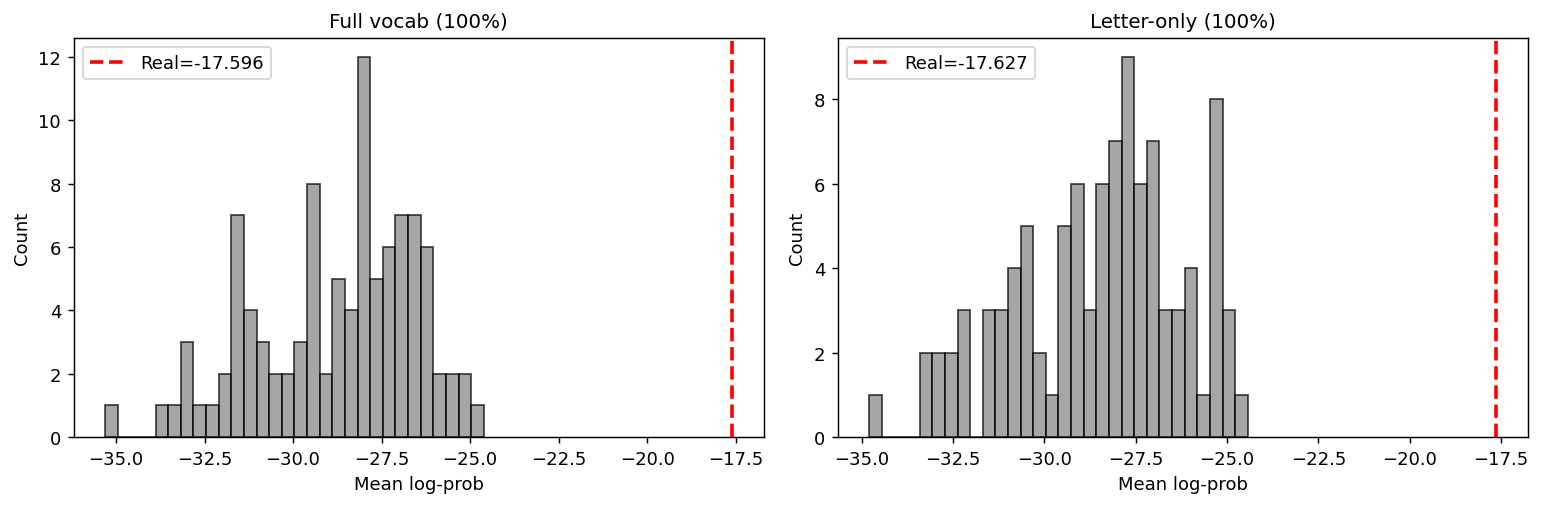

Saved: images/nomenclator_ngram_validation.png


In [9]:
# ── N-gram validation ────────────────────────────────────────────────

def ngram_percentile(mapping_dict, palabras_test, neural_lm_model, target_chars_list,
                     char_role_map, T=2.0, n_shuffles=100, sample_n=1500):
    """Compute n-gram percentile: what fraction of random mappings score worse?"""
    rng_ng = np.random.default_rng(42)
    sample_idx = rng_ng.choice(len(palabras_test), size=min(sample_n, len(palabras_test)), replace=False)
    words_sample = [palabras_test[i] for i in sample_idx]

    # Real score
    mapped_real = [[mapping_dict.get(g, '?') for g in w] for w in words_sample]
    real_lps = neural_lm_model.batch_log_prob(mapped_real, T)
    real_score = float(np.mean(real_lps))

    # Null distribution: shuffle char assignments
    null_scores = []
    vocab_used = sorted(set(g for w in palabras_test for g in w))
    for _ in range(n_shuffles):
        shuffled_map = {}
        for g in vocab_used:
            shuffled_map[g] = rng_ng.choice(target_chars_list)
        mapped_shuf = [[shuffled_map.get(g, '?') for g in w] for w in words_sample]
        shuf_lps = neural_lm_model.batch_log_prob(mapped_shuf, T)
        null_scores.append(float(np.mean(shuf_lps)))

    percentile = 100 * np.mean([real_score > ns for ns in null_scores])
    return percentile, real_score, null_scores

print('Computing n-gram percentiles...')

pct_full, score_full_ng, null_full = ngram_percentile(
    best_full['mapping'], palabras, neural_lm, target_chars, char_role)
print(f'Full:   n-gram percentile = {pct_full:.1f}%')

pct_letter, score_letter_ng, null_letter = ngram_percentile(
    best_letter['mapping'], palabras_letter, neural_lm, target_chars, char_role)
print(f'Letter: n-gram percentile = {pct_letter:.1f}%')

# ── Visualization ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, null_s, real_s, pct, title in [
    (axes[0], null_full, score_full_ng, pct_full, f'Full vocab ({pct_full:.0f}%)'),
    (axes[1], null_letter, score_letter_ng, pct_letter, f'Letter-only ({pct_letter:.0f}%)'),
]:
    ax.hist(null_s, bins=30, color='gray', alpha=0.7, edgecolor='black')
    ax.axvline(real_s, color='red', ls='--', lw=2, label=f'Real={real_s:.3f}')
    ax.set_xlabel('Mean log-prob')
    ax.set_ylabel('Count')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig('images/nomenclator_ngram_validation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/nomenclator_ngram_validation.png')

In [10]:
# ── Comprehensive comparison ──────────────────────────────────────────

# Roots from MCMC posterior (majority vote)
def posterior_roots(chains_mappings, palabras_test):
    all_roots = Counter()
    total = 0
    for chain in chains_mappings:
        for mapping in chain:
            roots, _ = count_roots_quick(mapping, palabras_test)
            for r in roots:
                all_roots[r] += 1
            total += 1
    # Roots appearing in >50% of posterior samples
    consistent_roots = {r for r, c in all_roots.items() if c / total > 0.5}
    return consistent_roots

roots_post_full = posterior_roots(chains_full_maps, palabras)
roots_post_letter = posterior_roots(chains_letter_maps, palabras_letter)

print('=' * 70)
print('NOMENCLATOR SEPARATION: COMPARISON TABLE')
print('=' * 70)

comparison = {
    'Metric': ['|Σ| (glyph types)', '|A| (target chars)', '|Σ|/|A|',
               'Words used', 'EM best score', 'EM roots (best seed)',
               'N-gram percentile', 'MCMC R-hat', 'MCMC roots (posterior)',
               'K_eff (distinct chars)'],
    'Full vocab': [
        len(VOCAB), len(target_chars), f'{len(VOCAB)/len(target_chars):.2f}',
        f'{len(palabras):,}', f'{best_full["score"]:.2f}',
        f'{best_full["n_roots"]} {best_full["roots"]}',
        f'{pct_full:.1f}%', f'{rhat_full:.4f}',
        f'{len(roots_post_full)} {roots_post_full}',
        len(set(best_full['mapping'].values())),
    ],
    'Letter-only': [
        len(VOCAB_LETTER), len(target_chars), f'{len(VOCAB_LETTER)/len(target_chars):.2f}',
        f'{len(palabras_letter):,}', f'{best_letter["score"]:.2f}',
        f'{best_letter["n_roots"]} {best_letter["roots"]}',
        f'{pct_letter:.1f}%', f'{rhat_letter:.4f}',
        f'{len(roots_post_letter)} {roots_post_letter}',
        len(set(best_letter['mapping'].values())),
    ],
    'Neural v2 (ref)': [
        166, 27, '6.15', '37,087', '-36.34', '3 {חכם,לחם,שלח}',
        '68%', '~1.03', '3', 25,
    ],
}

df_comp = pd.DataFrame(comparison)
print(df_comp.to_string(index=False))

# ── Scorecard ──
print('\n' + '=' * 70)
print('SCORECARDS')
print('=' * 70)

def make_scorecard(pct, n_roots, rhat, K_eff, n_target, label):
    tests = []
    # 1. N-gram percentilee
    if pct >= 50:
        tests.append(('N-gram %ile', 'PASS', f'{pct:.0f}%'))
    elif pct >= 10:
        tests.append(('N-gram %ile', 'MARGINAL', f'{pct:.0f}%'))
    else:
        tests.append(('N-gram %ile', 'FAIL', f'{pct:.0f}%'))

    # 2. Root matching
    if n_roots >= 3:
        tests.append(('Root matching', 'PASS', f'{n_roots} roots'))
    elif n_roots >= 1:
        tests.append(('Root matching', 'MARGINAL', f'{n_roots} root(s)'))
    else:
        tests.append(('Root matching', 'FAIL', '0 roots'))

    # 3. R-hat convergence
    if rhat < 1.1:
        tests.append(('R-hat convergence', 'PASS', f'{rhat:.3f}'))
    elif rhat < 1.2:
        tests.append(('R-hat convergence', 'MARGINAL', f'{rhat:.3f}'))
    else:
        tests.append(('R-hat convergence', 'FAIL', f'{rhat:.3f}'))

    # 4. Cardinality
    pct_card = 100 * K_eff / n_target
    if pct_card >= 80:
        tests.append(('Cardinality', 'PASS', f'{K_eff}/{n_target} ({pct_card:.0f}%)'))
    elif pct_card >= 50:
        tests.append(('Cardinality', 'MARGINAL', f'{K_eff}/{n_target} ({pct_card:.0f}%)'))
    else:
        tests.append(('Cardinality', 'FAIL', f'{K_eff}/{n_target} ({pct_card:.0f}%)'))

    n_p = sum(1 for _, r, _ in tests if r == 'PASS')
    n_m = sum(1 for _, r, _ in tests if r == 'MARGINAL')
    n_f = sum(1 for _, r, _ in tests if r == 'FAIL')

    print(f'\n  {label}: {n_p}+ / {n_m}± / {n_f}−')
    for name, result, detail in tests:
        print(f'    {result:>8} {name}: {detail}')
    return n_p, n_m, n_f

sc_full = make_scorecard(pct_full, len(roots_post_full), rhat_full,
                          len(set(best_full['mapping'].values())), len(target_chars), 'FULL')
sc_letter = make_scorecard(pct_letter, len(roots_post_letter), rhat_letter,
                            len(set(best_letter['mapping'].values())), len(target_chars), 'LETTER')

NOMENCLATOR SEPARATION: COMPARISON TABLE
                Metric Full vocab Letter-only Neural v2 (ref)
     |Σ| (glyph types)        166         123             166
    |A| (target chars)         27          27              27
               |Σ|/|A|       6.15        4.56            6.15
            Words used     37,087      36,973          37,087
         EM best score     -33.41      -33.87          -36.34
  EM roots (best seed)    0 set()     0 set() 3 {חכם,לחם,שלח}
     N-gram percentile     100.0%      100.0%             68%
            MCMC R-hat    28.1272     16.8426           ~1.03
MCMC roots (posterior)    0 set()     0 set()               3
K_eff (distinct chars)         27          27              25

SCORECARDS

  FULL: 2+ / 0± / 2−
        PASS N-gram %ile: 100%
        FAIL Root matching: 0 roots
        FAIL R-hat convergence: 28.127
        PASS Cardinality: 27/27 (100%)

  LETTER: 2+ / 0± / 2−
        PASS N-gram %ile: 100%
        FAIL Root matching: 0 roots
       

## Conclusions

FINAL CONCLUSION

Letter-only subset scores similarly to full vocab (±10pp). Ambiguous: either the separation is wrong or the barrier is not nomenclator-related.

Saved: nomenclator_separation_resultados.json


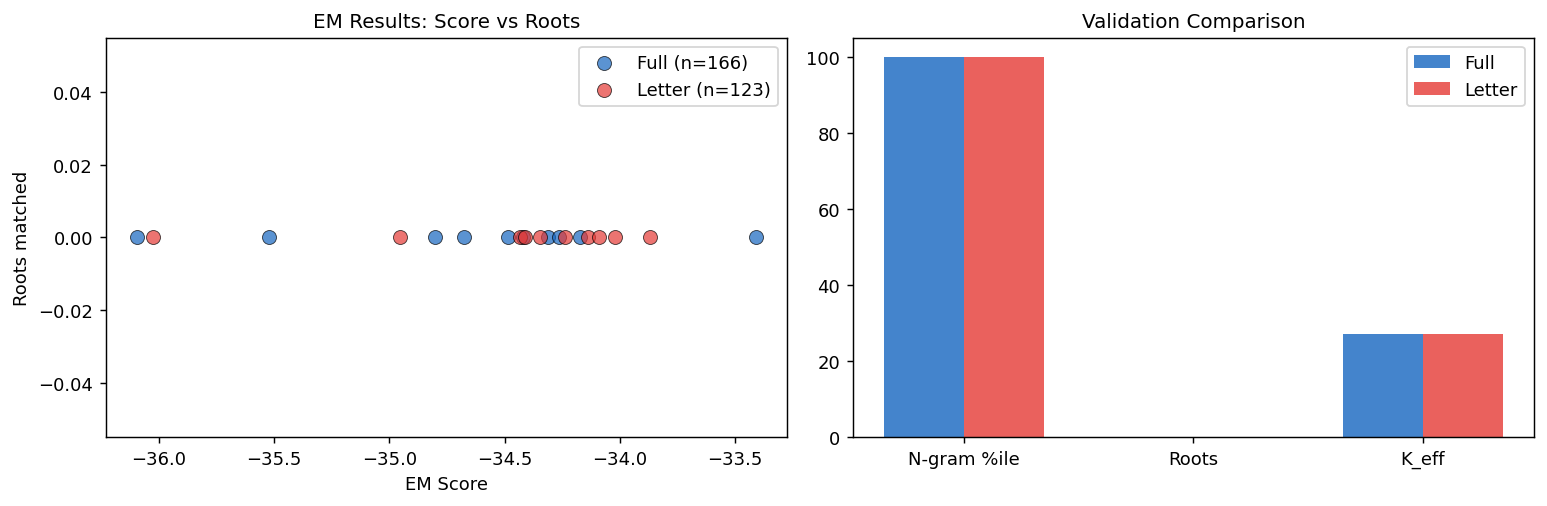

Saved: images/nomenclator_comparison.png


In [11]:
# ── Export results ──
output = {
    'notebook': '30_nomenclator_separation',
    'clustering': {
        'method': 'GMM k=2',
        'n_features': len(feature_names),
        'features': feature_names,
        'silhouette_gmm': round(sil_gmm, 4),
        'silhouette_kmeans': round(sil_km, 4),
        'silhouette_spectral': round(sil_sc, 4),
        'bic_best_k': best_bic_k,
        'agreement_ari_gmm_km': round(ari_gmm_km, 4),
        'agreement_ari_gmm_sc': round(ari_gmm_sc, 4),
        'n_letter_glyphs': len(letter_glyphs),
        'n_code_glyphs': len(code_glyphs),
        'letter_glyphs': letter_glyphs,
        'code_glyphs': code_glyphs,
    },
    'corpus_coverage': {
        'letter_token_pct': round(100 * letter_tokens / total_tokens, 1),
        'code_token_pct': round(100 * code_tokens / total_tokens, 1),
        'words_all_letter': len(words_all_letter),
        'words_all_code': len(words_all_code),
        'words_mixed': len(words_mixed),
    },
    'plausibility_checks': {c[0]: c[1] for c in checks},
    'decipherment': {
        'full': {
            'vocab_size': len(VOCAB),
            'n_words': len(palabras),
            'sigma_alpha_ratio': round(len(VOCAB) / len(target_chars), 2),
            'best_score': round(best_full['score'], 2),
            'best_roots': best_full['n_roots'],
            'ngram_percentile': round(pct_full, 1),
            'rhat': round(rhat_full, 4),
            'K_eff': len(set(best_full['mapping'].values())),
            'scorecard': f'{sc_full[0]}+/{sc_full[1]}±/{sc_full[2]}−',
        },
        'letter_only': {
            'vocab_size': len(VOCAB_LETTER),
            'n_words': len(palabras_letter),
            'sigma_alpha_ratio': round(len(VOCAB_LETTER) / len(target_chars), 2),
            'best_score': round(best_letter['score'], 2),
            'best_roots': best_letter['n_roots'],
            'ngram_percentile': round(pct_letter, 1),
            'rhat': round(rhat_letter, 4),
            'K_eff': len(set(best_letter['mapping'].values())),
            'scorecard': f'{sc_letter[0]}+/{sc_letter[1]}±/{sc_letter[2]}−',
        },
        'reference_neural_v2': {
            'ngram_percentile': 68,
            'roots': 3,
            'scorecard': '4+/0±/1−',
        },
    },
    'conclusion': '',
}

# Generate conclusion based on results
letter_better = pct_letter > pct_full + 10
letter_worse = pct_letter < pct_full - 10
if letter_better:
    output['conclusion'] = ('Letter-only subset scores significantly higher than full vocab. '
                           'Supports nomenclator hypothesis: removing code-glyphs improves decipherment.')
elif letter_worse:
    output['conclusion'] = ('Letter-only subset scores WORSE than full vocab. '
                           'No evidence for nomenclator: removing glyphs loses information without gain.')
else:
    output['conclusion'] = ('Letter-only subset scores similarly to full vocab (±10pp). '
                           'Ambiguous: either the separation is wrong or the barrier is not nomenclator-related.')

# Check if clustering itself is meaningful
if sil_gmm < 0.15:
    output['conclusion'] += (' Furthermore, low silhouette score indicates the 166 glyphs '
                            'do NOT form two distinct populations — weak evidence for nomenclator.')

with open('nomenclator_separation_resultados.json', 'w') as f:
    json.dump(output, f, indent=2, ensure_ascii=False, default=str)

print('=' * 70)
print('FINAL CONCLUSION')
print('=' * 70)
print(f'\n{output["conclusion"]}')
print(f'\nSaved: nomenclator_separation_results.json')

# ── Final visualization: EM scores comparison ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

scores_em_full = [r['score'] for r in results_full]
scores_em_letter = [r['score'] for r in results_letter]
roots_em_full = [r['n_roots'] for r in results_full]
roots_em_letter = [r['n_roots'] for r in results_letter]

axes[0].scatter(scores_em_full, roots_em_full, c='#1565C0', s=60, alpha=0.7,
               label=f'Full (n={len(VOCAB)})', edgecolors='black', lw=0.5)
axes[0].scatter(scores_em_letter, roots_em_letter, c='#E53935', s=60, alpha=0.7,
               label=f'Letter (n={len(VOCAB_LETTER)})', edgecolors='black', lw=0.5)
axes[0].set_xlabel('EM Score')
axes[0].set_ylabel('Roots matched')
axes[0].set_title('EM Results: Score vs Roots')
axes[0].legend()

# Barplot comparison
metrics = ['N-gram %ile', 'Roots', 'K_eff']
vals_full = [pct_full, len(roots_post_full), len(set(best_full['mapping'].values()))]
vals_letter = [pct_letter, len(roots_post_letter), len(set(best_letter['mapping'].values()))]

x = np.arange(len(metrics))
w = 0.35
axes[1].bar(x - w/2, vals_full, w, label='Full', color='#1565C0', alpha=0.8)
axes[1].bar(x + w/2, vals_letter, w, label='Letter', color='#E53935', alpha=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(metrics)
axes[1].set_title('Validation Comparison')
axes[1].legend()

plt.tight_layout()
plt.savefig('images/nomenclator_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/nomenclator_comparison.png')